internal nodeとexternal nodeでの変異獲得イベントの数のカウント
outgroup (SeCoV) baseで作成した系統樹で実施。

In [1]:
import pandas as pd

# 1. データの読み込み
# 提示されたテキストデータがスペース区切りの場合は sep='\s+' を指定
df = pd.read_csv('/Users/izumikida/FCoV_seq_relatives/treetime/NRR_ancestral_outgroup/output_NRR_2344/branch_mutations.txt', sep='\t')

# 2. ノードの分類フラグを作成
df['is_internal'] = df['node'].str.startswith('NODE')

# 3. pos ごとに集計
# sum() は True を 1 としてカウントし、(count - sum) で False の数を計算します
summary = df.groupby('pos')['is_internal'].agg(
    internal_node_count='sum',
    total_at_pos='count'
).reset_index()

# 4. カラムの計算と整理
summary['external_node_count'] = summary['total_at_pos'] - summary['internal_node_count']

# 見やすくするために順番を入れ替え
summary = summary[['pos', 'internal_node_count', 'external_node_count']]

# 結果の表示
print(summary.sort_values('pos'))

    pos  internal_node_count  external_node_count
0     1                    2                    1
1     2                    1                    0
2     3                    0                    6
3     4                    0                    2
4     5                    0                    1
5     6                    1                    0
6    13                    6                   11
7    15                    0                    1
8    16                    2                    9
9    17                    6                    3
10   21                    1                    1
11   24                    2                    5
12   26                    0                    3
13   27                    0                    4
14   28                    7                    6
15   29                    0                    3
16   30                   16                   13
17   31                   11                   21
18   32                    5                    5


In [2]:
# 5. pos の番号に 778 を加算
summary['pos'] = summary['pos'] + 778
summary

,pos,internal_node_count,external_node_count
0,779,2,1
1,780,1,0
2,781,0,6
3,782,0,2
4,783,0,1
5,784,1,0
6,791,6,11
7,793,0,1
8,794,2,9
9,795,6,3


In [3]:
# 1. 抽出したい番号のリストを作成
target_pos = [791, 809, 811, 813, 814, 826]

# 2. summaryからリストに含まれるposのみをフィルタリング
target_summary = summary[summary['pos'].isin(target_pos)].copy()

# 3. 結果の確認（昇順に並べ替え）
target_summary = target_summary.sort_values('pos')
print(target_summary)

# 4. TSVファイルとして保存
target_summary.to_csv('2344_mutation_summary.tsv', sep='\t', index=False)

    pos  internal_node_count  external_node_count
6   791                    6                   11
17  809                   11                   21
19  811                    3                    8
21  813                    1                    3
22  814                    5                   19
34  826                    2                    5


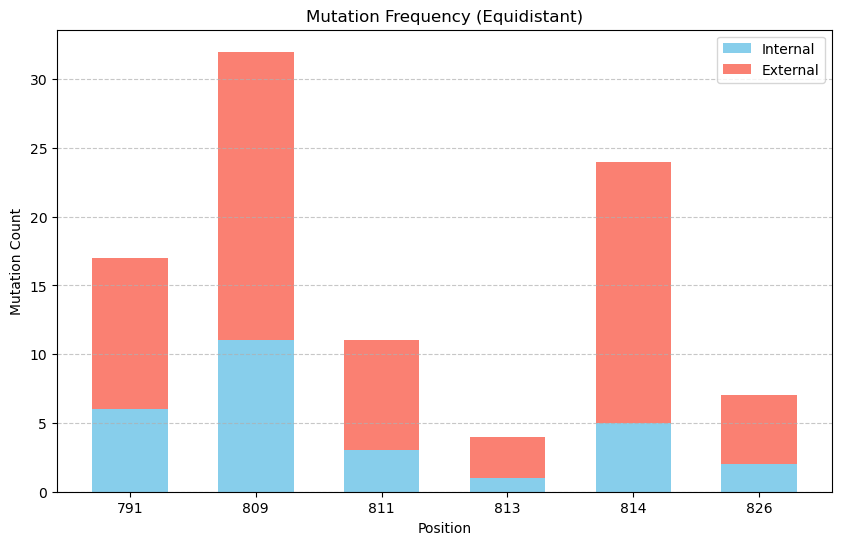

In [4]:
import matplotlib.pyplot as plt

# 元のデータ
pos = [791, 809, 811, 813, 814, 826]
internal = [6, 11, 3, 1, 5, 2]
external = [11, 21, 8, 3, 19, 5]

# x軸のインデックスを作成 (0, 1, 2, 3, 4, 5...)
x_indices = range(len(pos))

plt.figure(figsize=(10, 6))

# 積み上げ棒グラフ
# x軸にインデックスを指定
plt.bar(x_indices, internal, label='Internal', color='skyblue', width=0.6)
plt.bar(x_indices, external, bottom=internal, label='External', color='salmon', width=0.6)

# x軸の目盛りを元のpos値に戻す
plt.xticks(x_indices, pos) 

plt.xlabel('Position')
plt.ylabel('Mutation Count')
plt.title('Mutation Frequency (Equidistant)')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

In [5]:
import pandas as pd

# 1. データの読み込み
# 提示されたテキストデータがスペース区切りの場合は sep='\s+' を指定
df2 = pd.read_csv('/Users/izumikida/FCoV_seq_relatives/treetime/NRR_ancestral_outgroup/output_NRR_3129/branch_mutations.txt', sep='\t')

# 2. ノードの分類フラグを作成
df2['is_internal'] = df2['node'].str.startswith('NODE')

# 3. pos ごとに集計
# sum() は True を 1 としてカウントし、(count - sum) で False の数を計算します
summary2 = df2.groupby('pos')['is_internal'].agg(
    internal_node_count='sum',
    total_at_pos='count'
).reset_index()

# 4. カラムの計算と整理
summary2['external_node_count'] = summary2['total_at_pos'] - summary2['internal_node_count']

# 見やすくするために順番を入れ替え
summary2 = summary2[['pos', 'internal_node_count', 'external_node_count']]

# 結果の表示
print(summary2.sort_values('pos'))

    pos  internal_node_count  external_node_count
0     2                    0                    3
1     4                    0                    1
2    16                    2                    2
3    18                    0                    1
4    19                    6                   16
5    20                    0                    1
6    23                    1                    1
7    32                    0                    1
8    35                    8                   15
9    37                    1                    3
10   38                    0                    1
11   44                    1                    2
12   47                    1                    3
13   52                    0                    2
14   70                    0                    1
15   79                    1                    3
16   87                    0                    3
17   89                    0                    3
18   91                    0                    6


In [6]:
# 5. pos の番号に refに合うように　加算
summary2['pos'] = summary2['pos'] + 1037
summary2

,pos,internal_node_count,external_node_count
0,1039,0,3
1,1041,0,1
2,1053,2,2
3,1055,0,1
4,1056,6,16
5,1057,0,1
6,1060,1,1
7,1069,0,1
8,1072,8,15
9,1074,1,3


In [7]:
# 1. 抽出したい番号のリストを作成
target_pos2 = [1056,1072,1074,1078,1129]

# 2. summaryからリストに含まれるposのみをフィルタリング
target_summary2 = summary2[summary2['pos'].isin(target_pos2)].copy()

# 3. 結果の確認（昇順に並べ替え）
target_summary2 = target_summary2.sort_values('pos')
print(target_summary2)

# 4. TSVファイルとして保存
target_summary2.to_csv('3129_mutation_summary.tsv', sep='\t', index=False)

     pos  internal_node_count  external_node_count
4   1056                    6                   16
8   1072                    8                   15
9   1074                    1                    3
19  1129                    2                    2


In [8]:
import pandas as pd

# 1. データの読み込み
# 提示されたテキストデータがスペース区切りの場合は sep='\s+' を指定
df3 = pd.read_csv('/Users/izumikida/FCoV_seq_relatives/treetime/NRR_ancestral_outgroup/output_NRR_3423/branch_mutations.txt', sep='\t')

# 2. ノードの分類フラグを作成
df3['is_internal'] = df3['node'].str.startswith('NODE')

# 3. pos ごとに集計
# sum() は True を 1 としてカウントし、(count - sum) で False の数を計算します
summary3 = df3.groupby('pos')['is_internal'].agg(
    internal_node_count='sum',
    total_at_pos='count'
).reset_index()

# 4. カラムの計算と整理
summary3['external_node_count'] = summary3['total_at_pos'] - summary3['internal_node_count']

# 見やすくするために順番を入れ替え
summary3 = summary3[['pos', 'internal_node_count', 'external_node_count']]
summary3

,pos,internal_node_count,external_node_count
0,2,0,2
1,3,4,11
2,6,1,5
3,7,4,5
4,8,0,3
5,9,2,2
6,10,0,2
7,11,0,1
8,12,2,2
9,13,1,2


In [9]:
# 5. pos の番号に refに合うよう 加算
summary3['pos'] = summary3['pos'] + 1132
summary3

,pos,internal_node_count,external_node_count
0,1134,0,2
1,1135,4,11
2,1138,1,5
3,1139,4,5
4,1140,0,3
5,1141,2,2
6,1142,0,2
7,1143,0,1
8,1144,2,2
9,1145,1,2


In [10]:
# 1. 抽出したい番号のリストを作成
target_pos3 = [1135,1160]

# 2. summaryからリストに含まれるposのみをフィルタリング
target_summary3 = summary3[summary3['pos'].isin(target_pos3)].copy()

# 3. 結果の確認（昇順に並べ替え）
target_summary3 = target_summary3.sort_values('pos')
print(target_summary3)

# 4. TSVファイルとして保存
target_summary3.to_csv('3423_mutation_summary.tsv', sep='\t', index=False)

     pos  internal_node_count  external_node_count
1   1135                    4                   11
17  1160                    0                    7


In [11]:
import pandas as pd

# 1. データの読み込み
# 提示されたテキストデータがスペース区切りの場合は sep='\s+' を指定
df4 = pd.read_csv('/Users/izumikida/FCoV_seq_relatives/treetime/NRR_ancestral_outgroup/output_NRR_3558/branch_mutations.txt', sep='\t')

# 2. ノードの分類フラグを作成
df4['is_internal'] = df4['node'].str.startswith('NODE')

# 3. pos ごとに集計
# sum() は True を 1 としてカウントし、(count - sum) で False の数を計算します
summary4 = df4.groupby('pos')['is_internal'].agg(
    internal_node_count='sum',
    total_at_pos='count'
).reset_index()

# 4. カラムの計算と整理
summary4['external_node_count'] = summary4['total_at_pos'] - summary4['internal_node_count']

# 見やすくするために順番を入れ替え
summary4 = summary4[['pos', 'internal_node_count', 'external_node_count']]
summary4

,pos,internal_node_count,external_node_count
0,2,0,1
1,7,2,4
2,9,1,4
3,10,0,1
4,13,0,3
5,14,3,4
6,18,1,0
7,24,1,1
8,27,0,2
9,30,1,0


In [12]:
# 5. pos の番号に refに合うよう 加算
summary4['pos'] = summary4['pos'] + 1177
summary4

,pos,internal_node_count,external_node_count
0,1179,0,1
1,1184,2,4
2,1186,1,4
3,1187,0,1
4,1190,0,3
5,1191,3,4
6,1195,1,0
7,1201,1,1
8,1204,0,2
9,1207,1,0


In [13]:
# 1. 抽出したい番号のリストを作成
target_pos4 = [1212]

# 2. summaryからリストに含まれるposのみをフィルタリング
target_summary4 = summary4[summary4['pos'].isin(target_pos4)].copy()

# 3. 結果の確認（昇順に並べ替え）
target_summary4 = target_summary4.sort_values('pos')
print(target_summary4)

# 4. TSVファイルとして保存
target_summary4.to_csv('3558_mutation_summary.tsv', sep='\t', index=False)

     pos  internal_node_count  external_node_count
12  1212                    0                    5


In [14]:
import pandas as pd

# 1. データの読み込み
# 提示されたテキストデータがスペース区切りの場合は sep='\s+' を指定
df5 = pd.read_csv('/Users/izumikida/FCoV_seq_relatives/treetime/NRR_ancestral_outgroup/output_NRR_4109/branch_mutations.txt', sep='\t')

# 2. ノードの分類フラグを作成
df5['is_internal'] = df5['node'].str.startswith('NODE')

# 3. pos ごとに集計
# sum() は True を 1 としてカウントし、(count - sum) で False の数を計算します
summary5 = df5.groupby('pos')['is_internal'].agg(
    internal_node_count='sum',
    total_at_pos='count'
).reset_index()

# 4. カラムの計算と整理
summary5['external_node_count'] = summary5['total_at_pos'] - summary5['internal_node_count']

# 見やすくするために順番を入れ替え
summary5 = summary5[['pos', 'internal_node_count', 'external_node_count']]
summary5

,pos,internal_node_count,external_node_count
0,1,0,2
1,2,1,1
2,3,2,5
3,4,5,16
4,6,1,2
5,8,3,13
6,9,2,14
7,10,5,11
8,11,1,1
9,12,9,18


In [15]:
# 5. pos の番号に refに合うよう 加算
summary5['pos'] = summary5['pos'] + 1359
summary5

,pos,internal_node_count,external_node_count
0,1360,0,2
1,1361,1,1
2,1362,2,5
3,1363,5,16
4,1365,1,2
5,1367,3,13
6,1368,2,14
7,1369,5,11
8,1370,1,1
9,1371,9,18


In [16]:
# 1. 抽出したい番号のリストを作成
target_pos5 = [1363,1368]

# 2. summaryからリストに含まれるposのみをフィルタリング
target_summary5 = summary5[summary5['pos'].isin(target_pos5)].copy()

# 3. 結果の確認（昇順に並べ替え）
target_summary5 = target_summary5.sort_values('pos')
print(target_summary5)

# 4. TSVファイルとして保存
target_summary5.to_csv('4109_mutation_summary.tsv', sep='\t', index=False)

    pos  internal_node_count  external_node_count
3  1363                    5                   16
6  1368                    2                   14


In [17]:
import pandas as pd

# 1. 読み込むファイル名リスト
files = {
    '2344': '2344_mutation_summary.tsv',
    '3129': '3129_mutation_summary.tsv',
    '3423': '3423_mutation_summary.tsv',
    '3558': '3558_mutation_summary.tsv',
    '4109': '4109_mutation_summary.tsv'
}

# 2. リスト内包表記でデータを読み込み、ID列を追加
dfs = []
for nrr_id, file in files.items():
    df = pd.read_csv(file, sep='\t')
    df['nrr_id'] = nrr_id  # どのNRR由来かを示す列を追加
    dfs.append(df)

# 3. 結合（concat）
combined_df = pd.concat(dfs, ignore_index=True)

# 結果の表示
print(combined_df.head())

# 4. まとめたものを保存
combined_df.to_csv('combine_NRR_mutation_summary.tsv', sep='\t', index=False)

   pos  internal_node_count  external_node_count nrr_id
0  791                    6                   11   2344
1  809                   11                   21   2344
2  811                    3                    8   2344
3  813                    1                    3   2344
4  814                    5                   19   2344


In [18]:
df_all = pd.read_csv('/Users/izumikida/FCoV_seq_relatives/treetime/NRR_ancestral_outgroup/combine_NRR_mutation_summary.tsv', sep='\t')
df_all

,pos,internal_node_count,external_node_count,nrr_id
0,791,6,11,2344
1,809,11,21,2344
2,811,3,8,2344
3,813,1,3,2344
4,814,5,19,2344
5,826,2,5,2344
6,1056,6,16,3129
7,1072,8,15,3129
8,1074,1,3,3129
9,1129,2,2,3129


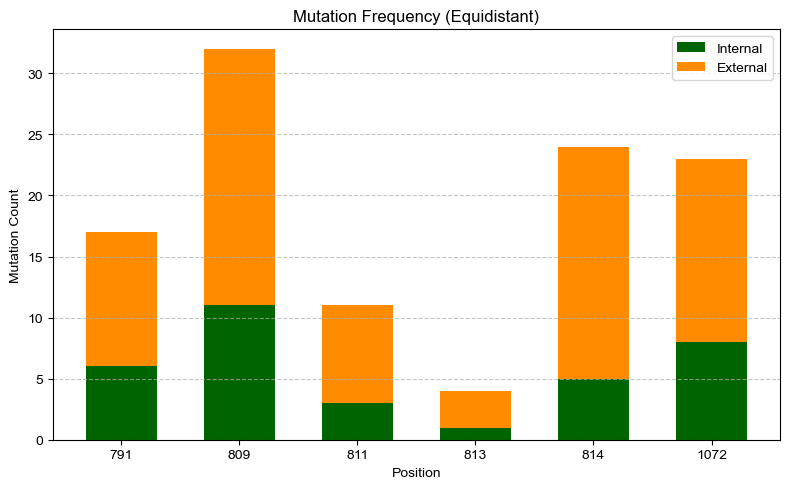

In [28]:
import matplotlib.pyplot as plt

# --- 1. Illustrator編集用 & フォントの設定 ---
# フォントをArialに指定
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial']

# 【重要】テキストをパス（図形）に変換せず、TrueTypeとしてPDFに埋め込む
# これによりIllustratorで「テキストツール」が使えます
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42

# --- 2. データの準備 ---
pos = [791, 809, 811, 813, 814, 1072]
internal = [6, 11, 3, 1, 5, 8]
external = [11, 21, 8, 3, 19, 15]

# --- 3. 色の定義 ---
color_external = "darkorange"
color_internal = "#006400"  # DarkGreen

# --- 4. グラフ描画 ---
plt.figure(figsize=(8, 5)) # 配置に合わせてサイズは調整してください
x_indices = range(len(pos))

# 積み上げ棒グラフ (指定色を適用)
plt.bar(x_indices, internal, label='Internal', color=color_internal, width=0.6)
plt.bar(x_indices, external, bottom=internal, label='External', color=color_external, width=0.6)

# --- 5. 軸とラベルの設定 ---
# x軸の目盛りを元のpos値に設定
plt.xticks(x_indices, pos) 

plt.xlabel('Position')
plt.ylabel('Mutation Count')
plt.title('Mutation Frequency (Equidistant)')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)

# レイアウトの自動調整
plt.tight_layout()

# --- 6. 保存設定 ---
# このファイルをIllustratorで「開く」ことで編集できます
plt.savefig("mutation_plot_final.pdf", format="pdf", bbox_inches='tight')

plt.show()

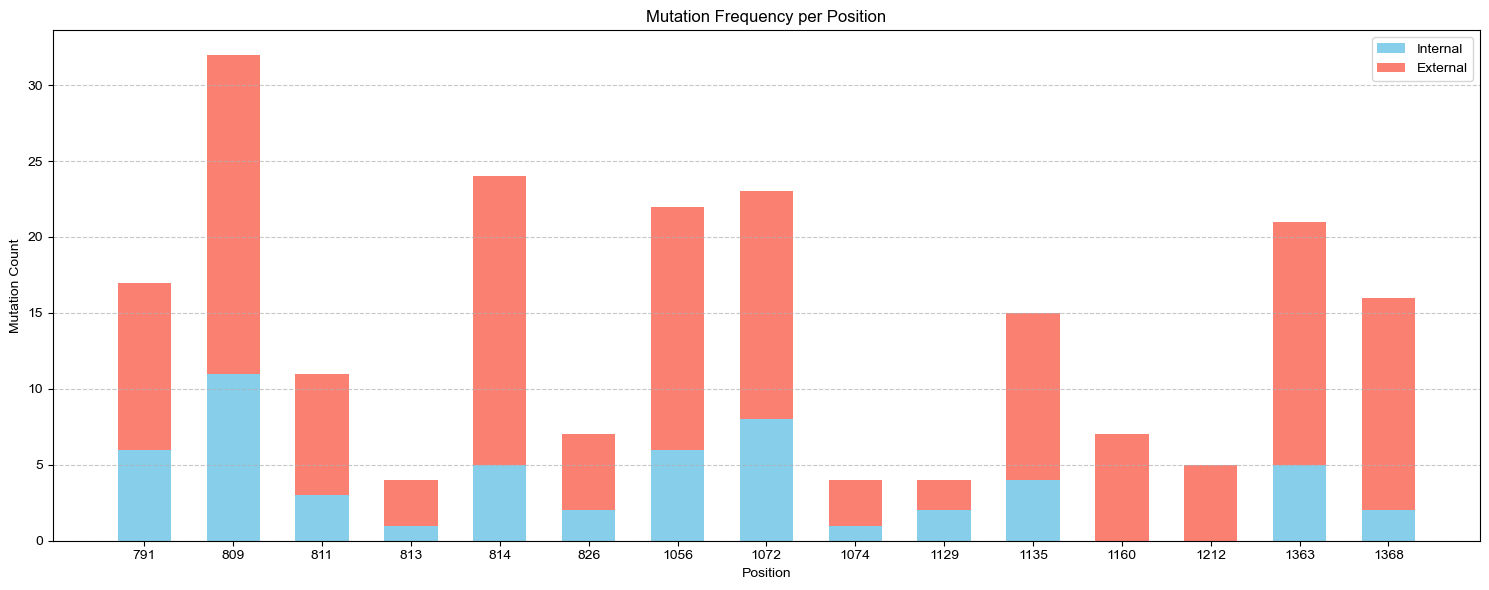

In [25]:
import matplotlib.pyplot as plt

# 1. データを整理 (すでに df_all があると仮定)
# posでソートしておくとグラフが綺麗になります
df_plot = df_all.sort_values('pos')

# 2. グラフ描画
plt.figure(figsize=(15, 6))

# 積み上げ棒グラフ
# x軸にはインデックス (range(len(df_plot))) を使い、等間隔に配置します
plt.bar(range(len(df_plot)), df_plot['internal_node_count'], label='Internal', color='skyblue', width=0.6)
plt.bar(range(len(df_plot)), df_plot['external_node_count'], bottom=df_plot['internal_node_count'], label='External', color='salmon', width=0.6)

# 3. 軸の調整
plt.xticks(range(len(df_plot)), df_plot['pos']) 
plt.xlabel('Position')
plt.ylabel('Mutation Count')
plt.title('Mutation Frequency per Position')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout() # ラベルがはみ出さないように調整
plt.show()

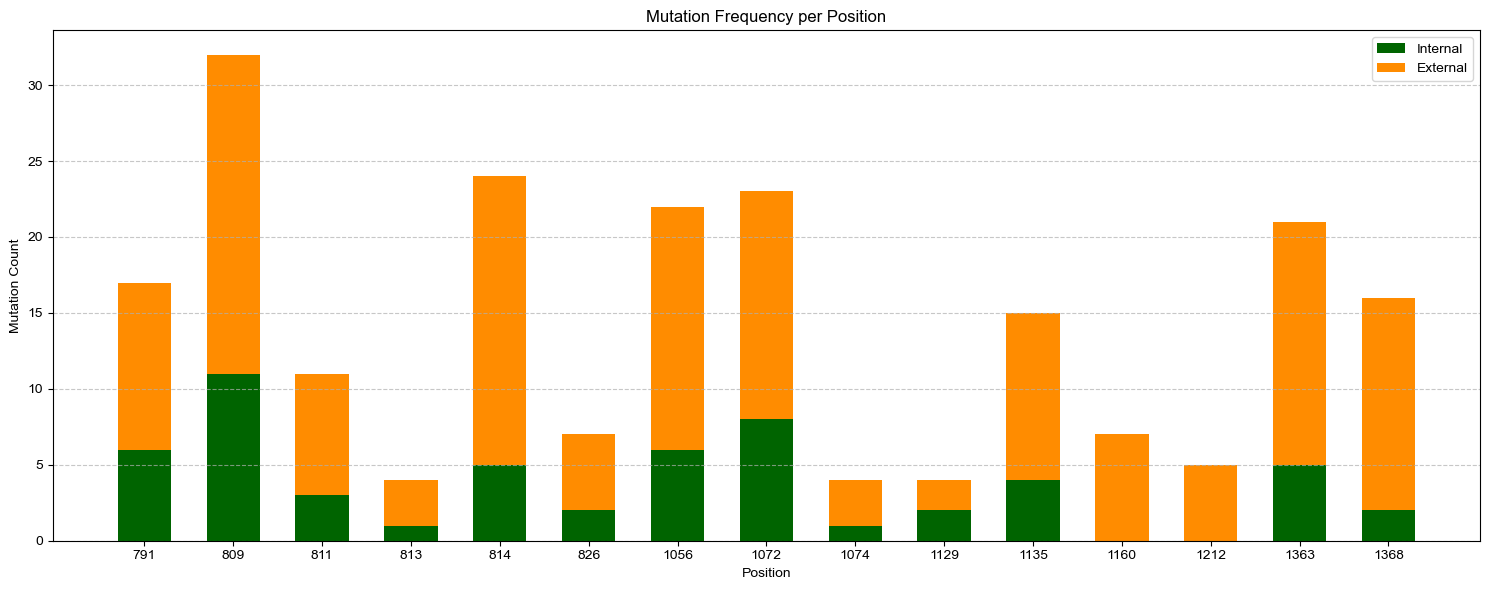

In [22]:
import matplotlib.pyplot as plt

# --- 1. Illustrator編集用 & フォントの設定 ---
# フォントをArialに指定
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial']

# 【重要】テキストをパスに変換せず、TrueTypeとしてPDFに埋め込む設定
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42

# --- 2. データの準備 (df_allがある前提) ---
df_plot = df_all.sort_values('pos')

# --- 3. 色の定義 ---
color_external = "darkorange"
color_internal = "#006400"  # DarkGreen

# --- 4. グラフ描画 ---
plt.figure(figsize=(15, 6))

# 積み上げ棒グラフ（定義した色を適用）
plt.bar(range(len(df_plot)), df_plot['internal_node_count'], 
        label='Internal', color=color_internal, width=0.6)

plt.bar(range(len(df_plot)), df_plot['external_node_count'], 
        bottom=df_plot['internal_node_count'], 
        label='External', color=color_external, width=0.6)

# --- 5. 軸の調整 ---
plt.xticks(range(len(df_plot)), df_plot['pos']) 
plt.xlabel('Position')
plt.ylabel('Mutation Count')
plt.title('Mutation Frequency per Position')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()

# --- 6. 保存設定 ---
# Illustratorで「開く」ことで、Arialフォントのまま編集可能になります
plt.savefig("mutation_plot_for_illustrator.pdf", format="pdf", bbox_inches='tight')

plt.show()